<center>

## Integración de Romberg

</center>

### Introducción

La integraciónn numerica permite aproximar una integral definida mediante evaluaciones de la función en determinados puntos. Uno de los métodos utilizados es la regla trapezoidal compuesta, que divide el intervalo de integracion en subintervalos de igual longitud y aproxima la integral mediante la suma de las areas de los trapecios correspondientes. Su error de truncamiento es de orden $O(h^2)$, donde $h$ representa la separación entre los nodos.
La integración de Romberg combina las aproximaciones de la regla trapezoidal compuesta con la extrapolación de Richardson donde su procedimiento consiste en reducir sucesivamente a la mitad la separación entre los nodos y combinar los resultados obtenidos para eliminar los terminos principales del error. De esta manera, se construyen aproximaciones de mayor orden para una integral de la forma

$$
I=\int_a^b f(x)\,dx.
$$

El metodo organiza los resultados en una tabla triangular. Cada nueva fila incorpora una aproximación trapezoidal y utiliza los valores anteriores para calcular las extrapolaciones restantes. Además, reutiliza las evaluaciones de la función, lo que permite mejorar la precisión sin repetir todos los calculos.

Para una función $f\in C^2[a,b]$, la regla trapezoidal compuesta se expresa como

$$
\int_a^b f(x)\,dx=\frac{h}{2}\left[f(a)+2\sum_{r=1}^{m-1}f(x_r)+f(b)\right]-\frac{b-a}{12}h^2f''(\mu),
$$

donde

$$
h=\frac{b-a}{m},\qquad x_r=a+rh,\qquad r=0,1,\ldots,m,
$$

y $\mu\in(a,b)$. Aquí, $m$ representa el número de subintervalos. El término que contiene $h^2$ corresponde al error de la aproximación.

Si $f\in C^\infty[a,b]$, el error puede escribirse mediante una expansión asintotica en potencias pares de $h$:

$$
I=T(h)+K_1h^2+K_2h^4+K_3h^6+\cdots,
$$

donde

$$
T(h)=\frac{h}{2}\left[f(a)+2\sum_{r=1}^{m-1}f(x_r)+f(b)\right].
$$

Las constantes $K_i$ dependen de las derivadas de orden $2i-1$ de la función en los extremos del intervalo. Esta estructura del error permite aplicar la extrapolación de Richardson para eliminar sucesivamente los terminos de orden $h^2$, $h^4$, $h^6$, entre otros

Para construir la tabla de Romberg, se calculan aproximaciones trapezoidales con

$$
m_k=2^{k-1},\qquad h_k=\frac{b-a}{2^{k-1}},\qquad k=1,2,\ldots,n.
$$

Por tanto, el numero de subintervalos sigue la sucesión $1,2,4,8,\ldots$, mientras que la separación entre los nodos se reduce a la mitad en cada paso. El entero positivo $n$ indica el número de filas de la tabla.

La primera aproximación utiliza unicamente los extremos del intervalo:

$$
R_{1,1}=\frac{b-a}{2}\left[f(a)+f(b)\right].
$$

Las siguientes aproximaciones de la primera columna se obtienen mediante

$$
R_{k,1}=\frac{1}{2}\left[R_{k-1,1}+h_{k-1}\sum_{i=1}^{2^{k-2}}f\left(a+(2i-1)h_k\right)\right],\qquad k=2,3,\ldots,n.
$$

Esta expresión reutiliza la aproximación anterior y añade las evaluaciones en los puntos medios de sus subintervalos.

Despues se aplica la extrapolación. La segunda columna se calcula con

$$
R_{k,2}=R_{k,1}+\frac{R_{k,1}-R_{k-1,1}}{3},\qquad k=2,3,\ldots,n,
$$

y proporciona aproximaciones de orden $O(h_k^4)$. La tercera columna se obtiene mediante

$$
R_{k,3}=R_{k,2}+\frac{R_{k,2}-R_{k-1,2}}{15},\qquad k=3,4,\ldots,n,
$$

con aproximaciones de orden $O(h_k^6)$.

En general, la fórmula de extrapolación es

$$
R_{k,j}=R_{k,j-1}+\frac{R_{k,j-1}-R_{k-1,j-1}}{4^{j-1}-1},\qquad j=2,3,\ldots,k.
$$

Bajo las condiciones de suavidad necesarias, cada columna $j$ tiene un error de orden $O(h_k^{2j})$. Las primeras filas se organizan de la siguiente manera:

$$
\begin{array}{c|cccc}
k & O(h_k^2) & O(h_k^4) & O(h_k^6) & O(h_k^8)\\
\hline
1 & R_{1,1} & & &\\
2 & R_{2,1} & R_{2,2} & &\\
3 & R_{3,1} & R_{3,2} & R_{3,3} &\\
4 & R_{4,1} & R_{4,2} & R_{4,3} & R_{4,4}
\end{array}
$$

La tabla se construye una fila completa a la vez. En cada fila se calcula primero la aproximación trapezoidal y después las extrapolaciones. Al terminar las $n$ filas, se toma $R_{n,n}$ como aproximación de la integral. La mejora del orden depende de que la función tenga suficientes derivadas continuas en el intervalo. Existe la condición $f\in C^{2k+2}[a,b]$ para justificar la expansión utilizada al generar la fila $k$.


### Integración de Romberg en Python

In [27]:
def romberg(f, a, b, n): #Variables de entrada
    if not isinstance(n, int) or n <= 0:  #Verifica que n sea un entero positivo
        raise ValueError("n debe ser un entero positivo.")  # Detiene el calculo si n no es valido
    R = [[0.0] * n for _ in range(n)] #Crea una matriz para guardar la tabla
    h = b - a #Establece la longitud inicial del intervalo
    R[0][0] = h * (f(a) + f(b)) /2  #Calcula la primera aproximación trapezoidal

    for i in range(1, n):  #Construye las filas desde la segunda hasta la última
        suma = 0  #Inicializa la suma de las nuevas evaluaciones
        for k in range(1, 2**(i - 1) + 1):    #Recorre los nuevos puntos medios
            x = a + (k - 0.5) * h #Calcula la posición de cada punto medio
            suma = suma + f(x)    #Acumula las evaluaciones de la función
        R[i][0] = (R[i - 1][0] + h * suma)/2#Actualiza la aproximación trapezoidal
        for j in range(1, i + 1):  #Recorre las columnas de extrapolación de esta fila
            R[i][j] = R[i][j - 1]+(R[i][j - 1] - R[i - 1][j - 1]) /(4**j - 1)#Aplica la extrapolación de Richardson
        h = h / 2  #Reduce la separación entre nodos para la siguiente fila
    return R  # Devuelve la tabla de Romberg

### Ejemplo

Hallar una aproximación de la integral

$$
I=\int_0^\pi \sin(x)\,dx,
$$

mediante la integración de Romberg, construyendo una tabla de $n=6$ filas y tomando $R_{6,6}$ como aproximación final.

### Aplicando el codigo

In [28]:
import math #Libreria que permite usar funciones matematicas

def f(x):# Define la función que se integrara
    return math.sin(x)
a = 0  # Establece el limite inferior
b = math.pi#Establece el limite superior
n = 6  #Indica que se construiran seis filas
R = romberg(f, a, b, n)  #Llama a la función
for i in range(n):  # Recorre las filas de la tabla
    for j in range(i + 1):  # Recorre unicamente las entradas calculadas de cada fila
        print(f"{R[i][j]:.10f}", end="  ")  #Resultado con 10 decimales
    print() #Pasa a la siguiente linea al terminar cada fila
resultado = R[n - 1][n - 1]  # Obtiene R6,6
print(f"\nAproximacion de la integral: {resultado:.10f}")  # Muestra el resultado

0.0000000000  
1.5707963268  2.0943951024  
1.8961188979  2.0045597550  1.9985707318  
1.9742316019  2.0002691699  1.9999831309  2.0000055500  
1.9935703438  2.0000165910  1.9999997525  2.0000000163  1.9999999946  
1.9983933610  2.0000010334  1.9999999962  2.0000000001  2.0000000000  2.0000000000  

Aproximacion de la integral: 2.0000000000


### Grafia de la integral


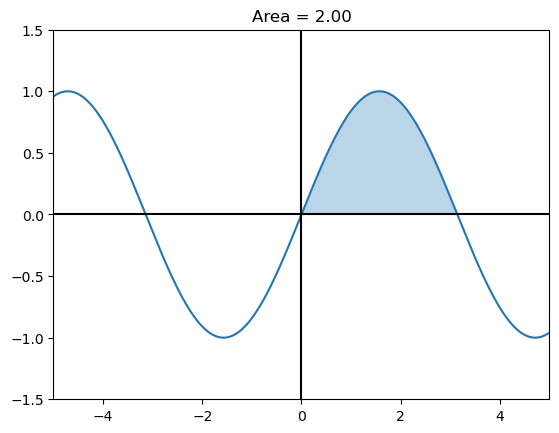

In [25]:
import numpy as np 
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 2001)#Crea puntos para graficar desde -5 hasta 5
y = np.sin(x)  #Evalúa la función seno en esos puntos
x_area = np.linspace(0, np.pi, 1001)  #Crea puntos del intervalo [0, pi]
y_area = np.sin(x_area)  #Evalua la función en el intervalo que se sombreara
plt.plot(x, y)  #Dibuja la función seno
plt.fill_between(x_area, y_area, 0, alpha=0.3)  #Sombrea el area entre la curva y el eje x en [0, pi]
plt.axhline(0, color="black")#Dibuja el eje horizontal
plt.axvline(0, color="black") #Dibuja el eje vertical
plt.xlim(-5, 5)  #Establece los limites visibles del eje x
plt.ylim(-1.5, 1.5)  #Ajusta el eje y para apreciar la función seno
plt.title(f"Area = {resultado:.2f}")
plt.show()  #Muestra la grafica.

### Conclusión
La integración de Romberg permitio aproximar la integral mediante una tabla de seis filas, obteniendo

$$
I=\int_0^\pi \sin(x)\,dx = 2.0
$$

El resultado coincide con el valor exacto de la integral en las cifras mostradas. La tabla refleja cómo el refinamiento del intervalo y la extrapolación de Richardson permiten mejorar la precisión, aprovechando las evaluaciones anteriores de la función. Esta precisión depende del numero de filas que se escoja y de la suavidad de cada funcion.